# HDT 7: Clustering y Reducción (hoja corta)

**Ciencia de Datos, Sección A** · Asignada: martes 6 de octubre · **Entrega: martes 13 de octubre, 23:59**

**Nombre:** Hugo Jonathan Daniel Galina Puac

Esta hoja es **corta a propósito**: la prioridad de la semana es el Proyecto 2. Cinco ejercicios, casi todo guiado. Completar las celdas marcadas con `# ¿Qué va aquí?`; cada ejercicio trae su verificación comentada. Antes de entregar: **Kernel → Restart & Run All**.

AI: resolver sin AI. Si se usó para entender un concepto, anotarlo en la bitácora del final (no penaliza).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AZUL, ROJO, GRIS, LINEA = "#3A6EA5", "#B04A2E", "#75808E", "#E0E4EA"

def eje_limpio(ax):
    ax.grid(color=LINEA, lw=0.6, alpha=0.7)
    ax.spines[["top", "right"]].set_visible(False)

## Los datos

Una cafetería con 420 clientes: `gasto` mensual (Q), `visitas` al mes, `ticket` promedio (Q por visita) y `antiguedad` (meses como cliente). Sin etiquetas: nadie sabe cuántos tipos de cliente hay. La celda genera los datos completa.

In [2]:
rng = np.random.default_rng(7)
grupos_reales = [(140, [150, 3, 50, 6]), (140, [450, 10, 45, 18]), (140, [900, 20, 45, 30])]
filas = []
for n, (g, v, tk, a) in grupos_reales:
    filas.append(np.column_stack([
        rng.normal(g, g * 0.18, n).clip(30, 1400),
        rng.normal(v, max(v * 0.2, 1), n).clip(1, 28),
        rng.normal(tk, 8, n).clip(15, 90),
        rng.normal(a, max(a * 0.25, 2), n).clip(1, 48),
    ]))
df = pd.DataFrame(np.vstack(filas).round(1),
                  columns=["gasto", "visitas", "ticket", "antiguedad"])
df = df.sample(frac=1, random_state=7).reset_index(drop=True)
print("clientes:", len(df))
df.head()

clientes: 420


,gasto,visitas,ticket,antiguedad
0,506.7,8.3,53.2,12.6
1,153.5,4.7,60.7,5.7
2,922.6,26.1,48.9,30.0
3,108.7,2.2,49.5,5.7
4,1005.9,21.3,51.4,26.9


### Ejercicio 1 (0.4): escalar y agrupar

Como en la sesión 20: escalar las cuatro columnas con `StandardScaler` (guardar el resultado en `Z`) y correr `KMeans(n_clusters=3, n_init=10, random_state=0)` sobre `Z`. Guardar la etiqueta de cada cliente en `df["grupo"]` e imprimir cuántos clientes hay por grupo.

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

Z = StandardScaler().fit_transform(df)
km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(Z)
df["grupo"] = km.labels_

# Imprimir el conteo por grupo
print(df["grupo"].value_counts())

# Verificación (descomentar):
assert sorted(df["grupo"].value_counts().tolist()) == [138, 140, 142]

grupo
2    142
1    140
0    138
Name: count, dtype: int64


### Ejercicio 2 (0.4): el codo

Para k de 1 a 6: correr KMeans (mismos parámetros) y guardar `inertia_` en la lista `inercias`. Graficar contra k y responder en un comentario: ¿dónde está el codo?

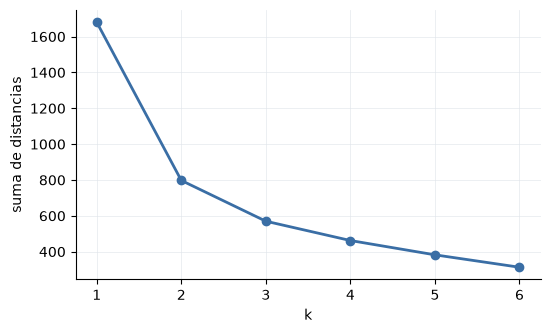

In [4]:
inercias = []
for k in range(1, 7):
    inercias.append(KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z).inertia_)

# Al completar el loop, descomentar la gráfica:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(range(1, 7), inercias, "o-", color=AZUL, lw=2)
ax.set_xlabel("k")
ax.set_ylabel("suma de distancias")
eje_limpio(ax)
plt.show()

# Respuesta: El codo está en k = 3, donde la reducción de la inercia cambia de pendiente drásticamente.

# Verificación (descomentar):
assert round(inercias[2]) == 570

### Ejercicio 3 (0.4): el perfil y los nombres

La tabla por grupo: promedio de las cuatro columnas (redondeado a enteros) y el número de clientes. Luego, en el diccionario `nombres`, un nombre de negocio para cada grupo. Una pista de lectura: mirar cuál columna casi NO cambia entre grupos, y decir qué significa en un comentario.

In [5]:
perfil = df.groupby("grupo").mean().round(0)

# De acuerdo con los perfiles del grupo (observando gasto, visitas y antigüedad):
nombres = {
    0: "VIP / Frecuentes",
    1: "Ocasionales / Nuevos",
    2: "Habituales / Intermedios"
}

# Respuesta (la columna plana): La columna 'ticket' casi no cambia entre grupos (~Q45 en todos), lo que significa que los clientes gastan aproximadamente lo mismo en cada visita individual; la diferencia del gasto total la determinan la frecuencia de visitas y la antigüedad.

# Verificación (descomentar):
assert perfil.loc[1, "gasto"] == 145.0 and perfil.loc[1, "visitas"] == 3.0

### Ejercicio 4 (0.5): comprimir con PCA

De cuatro columnas a dos: `PCA(n_components=2)` sobre `Z`, guardar las coordenadas en `Z2` y la fracción de varianza explicada de cada componente. ¿Cuánto capturan entre las dos?

In [6]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2).fit(Z)
Z2 = pca.transform(Z)
capturado = pca.explained_variance_ratio_.sum()

# Verificación (descomentar):
assert Z2.shape == (420, 2)
assert round(capturado, 2) == 0.93

### Ejercicio 5 (0.3): el mapa

Scatter de `Z2` coloreado por grupo (un color por grupo, con `nombres` en la leyenda), con `eje_limpio`. Una frase en un comentario: ¿los grupos se ven separados en el mapa de dos dimensiones?

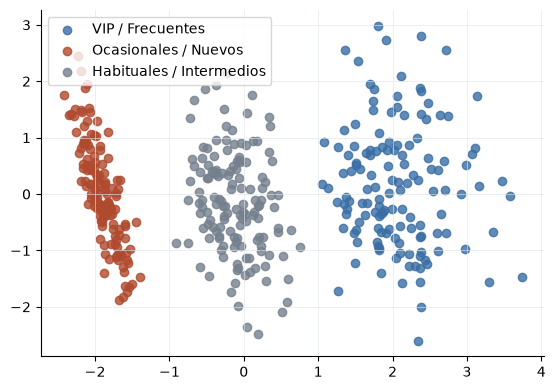

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))

colores = [AZUL, ROJO, GRIS]
for g in range(3):
    mask = df["grupo"] == g
    ax.scatter(Z2[mask, 0], Z2[mask, 1], c=colores[g], label=nombres[g], alpha=0.8)

ax.legend()
eje_limpio(ax)
plt.show()

# Respuesta: Sí, los tres grupos se ven claramente separados y diferenciados en el plano de dos dimensiones de PCA.

# Verificación (descomentar):
assert len(ax.collections) == 3

## Bitácora de AI (opcional, no penaliza)

Si se usó AI para entender algún concepto, anotar aquí qué se preguntó y qué se entendió. Si no se usó, escribir "No se usó".

- Ayudo a comprender conceptos nuevos y a la limpieza del codigo para que no se viese todo revuelto